In [1]:
dataset_path = "archive (1)/dataset"

In [2]:
import os

os.path.exists(dataset_path)

True

In [3]:
class_names = os.listdir(dataset_path)
print(class_names)

['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___healthy', 'Corn_(maize)___Northern_Leaf_Blight', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_healthy', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_mosaic_virus', 'Tomato__Tomato_YellowLeaf__Curl_Virus']


In [4]:
num_classes = len(class_names)

print("Number of classes:", num_classes)

Number of classes: 23


In [5]:
total_images = 0

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    total_images += len(os.listdir(class_path))

print("Total images:", total_images)

Total images: 35726


In [6]:
for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    image_count = len(os.listdir(class_path))
    
    print(class_name, ":", image_count)

Apple___Apple_scab : 2016
Apple___Black_rot : 1987
Apple___Cedar_apple_rust : 1760
Apple___healthy : 2008
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot : 1642
Corn_(maize)___Common_rust_ : 1907
Corn_(maize)___healthy : 1859
Corn_(maize)___Northern_Leaf_Blight : 1908
Pepper__bell___Bacterial_spot : 997
Pepper__bell___healthy : 1478
Potato___Early_blight : 1000
Potato___healthy : 152
Potato___Late_blight : 1000
Tomato_Bacterial_spot : 2127
Tomato_Early_blight : 1000
Tomato_healthy : 1591
Tomato_Late_blight : 1909
Tomato_Leaf_Mold : 952
Tomato_Septoria_leaf_spot : 1771
Tomato_Spider_mites_Two_spotted_spider_mite : 1676
Tomato__Target_Spot : 1404
Tomato__Tomato_mosaic_virus : 373
Tomato__Tomato_YellowLeaf__Curl_Virus : 3209


In [7]:
import tensorflow as tf

print(tf.__version__)

2.21.0


In [8]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

In [9]:
class_name = class_names[0]

class_path = os.path.join(dataset_path, class_name)

image_name = os.listdir(class_path)[0]

image_path = os.path.join(class_path, image_name)

print("Class:", class_name)
print("Image:", image_name)
print("Image path:", image_path)

Class: Apple___Apple_scab
Image: 00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG
Image path: archive (1)/dataset\Apple___Apple_scab\00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG


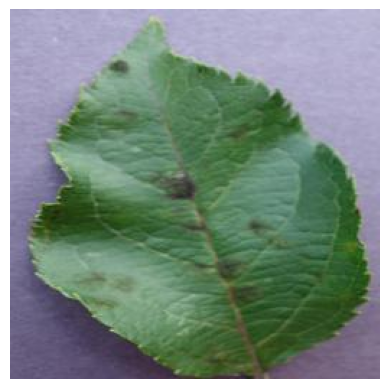

In [10]:
img = plt.imread(image_path)

plt.imshow(img)
plt.axis("off")
plt.show()

In [11]:
print(img.shape)

(256, 256, 3)


In [12]:
for i in range(5):
    image_name = os.listdir(class_path)[i]
    image_path = os.path.join(class_path, image_name)
    
    img = plt.imread(image_path)
    
    print(image_name, "→", img.shape)

00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG → (256, 256, 3)
01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003.JPG → (256, 256, 3)
01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003_270deg.JPG → (256, 256, 3)
01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003_90deg.JPG → (256, 256, 3)
01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003_new30degFlipLR.JPG → (256, 256, 3)


In [13]:
img_resized = tf.image.resize(img, (128, 128))

print(img_resized.shape)

(128, 128, 3)


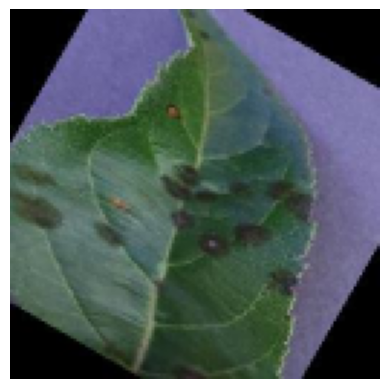

In [14]:
plt.imshow(img_resized.numpy().astype("uint8"))
plt.axis("off")
plt.show()

In [15]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=(128, 128),
    batch_size=32
)

Found 35725 files belonging to 23 classes.


In [16]:
train_size = int(0.8 * len(train_dataset))

train_data = train_dataset.take(train_size)
remaining_data = train_dataset.skip(train_size)

print("Training batches:", len(train_data))
print("Remaining batches:", len(remaining_data))

Training batches: 893
Remaining batches: 224


In [17]:
val_size = len(remaining_data) // 2

val_data = remaining_data.take(val_size)
test_data = remaining_data.skip(val_size)

print("Validation batches:", len(val_data))
print("Test batches:", len(test_data))

Validation batches: 112
Test batches: 112


In [18]:
images, labels = next(iter(train_data))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: (32, 128, 128, 3)
Labels shape: (32,)


In [19]:
print(labels)

tf.Tensor(
[ 8  9  5 13 16  6 14  6 22 17  2  5  7  0  8 22  3  5 18  6 17  4  2  1
 16  5  3  9  9 20  2  9], shape=(32,), dtype=int32)


In [20]:
train_data = train_data.map(lambda x, y: (x / 255.0, y))
val_data = val_data.map(lambda x, y: (x / 255.0, y))
test_data = test_data.map(lambda x, y: (x / 255.0, y))

In [21]:
images, labels = next(iter(train_data))

print(tf.reduce_min(images).numpy())
print(tf.reduce_max(images).numpy())

0.0
1.0


In [22]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [23]:
image = images[0]

In [24]:
augmented_image = data_augmentation(tf.expand_dims(image, 0))

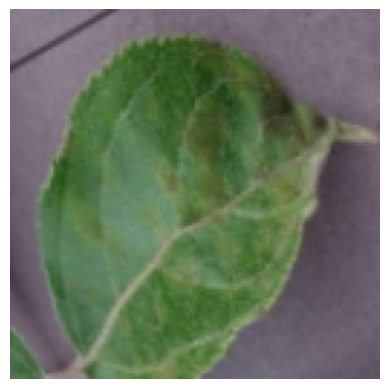

In [25]:
plt.imshow(augmented_image[0].numpy())
plt.axis("off")
plt.show()

In [26]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(128, 128, 3)),

    data_augmentation,

    tf.keras.layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    tf.keras.layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dense(
        23,
        activation="softmax"
    )
])

In [27]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     8,388,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 23)             │         2,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,411,095 (32.09 MB)

 Trainable params: 8,411,095 (32.09 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [29]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10


c:\Users\Hp\Desktop\Plant Disease Prediction\dl_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


893/893 ━━━━━━━━━━━━━━━━━━━━ 426s 472ms/step - accuracy: 0.6337 - loss: 1.1866 - val_accuracy: 0.7227 - val_loss: 0.8854
Epoch 2/10
893/893 ━━━━━━━━━━━━━━━━━━━━ 382s 427ms/step - accuracy: 0.8116 - loss: 0.5773 - val_accuracy: 0.8206 - val_loss: 0.5868
Epoch 3/10
893/893 ━━━━━━━━━━━━━━━━━━━━ 429s 481ms/step - accuracy: 0.8545 - loss: 0.4411 - val_accuracy: 0.8351 - val_loss: 0.5223
Epoch 4/10
893/893 ━━━━━━━━━━━━━━━━━━━━ 366s 410ms/step - accuracy: 0.8817 - loss: 0.3541 - val_accuracy: 0.8714 - val_loss: 0.4013
Epoch 5/10
893/893 ━━━━━━━━━━━━━━━━━━━━ 333s 372ms/step - accuracy: 0.8951 - loss: 0.3092 - val_accuracy: 0.8424 - val_loss: 0.5207
Epoch 6/10
893/893 ━━━━━━━━━━━━━━━━━━━━ 335s 375ms/step - accuracy: 0.9069 - loss: 0.2784 - val_accuracy: 0.8139 - val_loss: 0.6115
Epoch 7/10
893/893 ━━━━━━━━━━━━━━━━━━━━ 334s 374ms/step - accuracy: 0.9189 - loss: 0.2364 - val_accuracy: 0.9169 - val_loss: 0.2596
Epoch 8/10
893/893 ━━━━━━━━━━━━━━━━━━━━ 327s 366ms/step - accuracy: 0.9239 - loss: 0.22

In [30]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

112/112 ━━━━━━━━━━━━━━━━━━━━ 23s 113ms/step - accuracy: 0.8853 - loss: 0.3560
Test Loss: 0.3560485541820526
Test Accuracy: 0.8852735161781311


In [31]:
y_true = []
y_pred = []

for images, labels in test_data:
    predictions = model.predict(images, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

In [32]:
print("Actual labels:", len(y_true))
print("Predicted labels:", len(y_pred))

Actual labels: 3565
Predicted labels: 3565


In [34]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

print(cm)

[[183  17   1   7   0   0   0   0   0   1   0   1   0   0   1   1   6   3
    0   0   0   0   3]
 [  0 189   0   1   0   0   0   0   0   1   0   0   0   0   0   0   0   1
    0   0   0   0   0]
 [  0   0 175   1   0   0   0   0   0   1   0   0   0   0   0   4   0   0
    0   0   0   0   0]
 [  2   5   0 177   0   0   0   0   0   5   0   0   1   0   8   1   1   1
    1   0   0   0   2]
 [  0   0   0   0 133   0  22   1   1   0   0   0   0   0   1   2   0   0
    0   0   0   0   0]
 [  0   0   0   0   1 184   0   0   0   0   0   0   0   0   0   1   0   0
    0   0   0   0   0]
 [  0   0   0   0   1   0 192   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0]
 [  0   0   0   0   1   0   2 194   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0]
 [  0   2   0   0   0   0   0   0  82   4   0   0   0   0   1   0   0   0
    0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 138   0   0   1   0   1   0   0   0
    0   0   0   0   0]
 [  0   0   0   0   0   0   0 

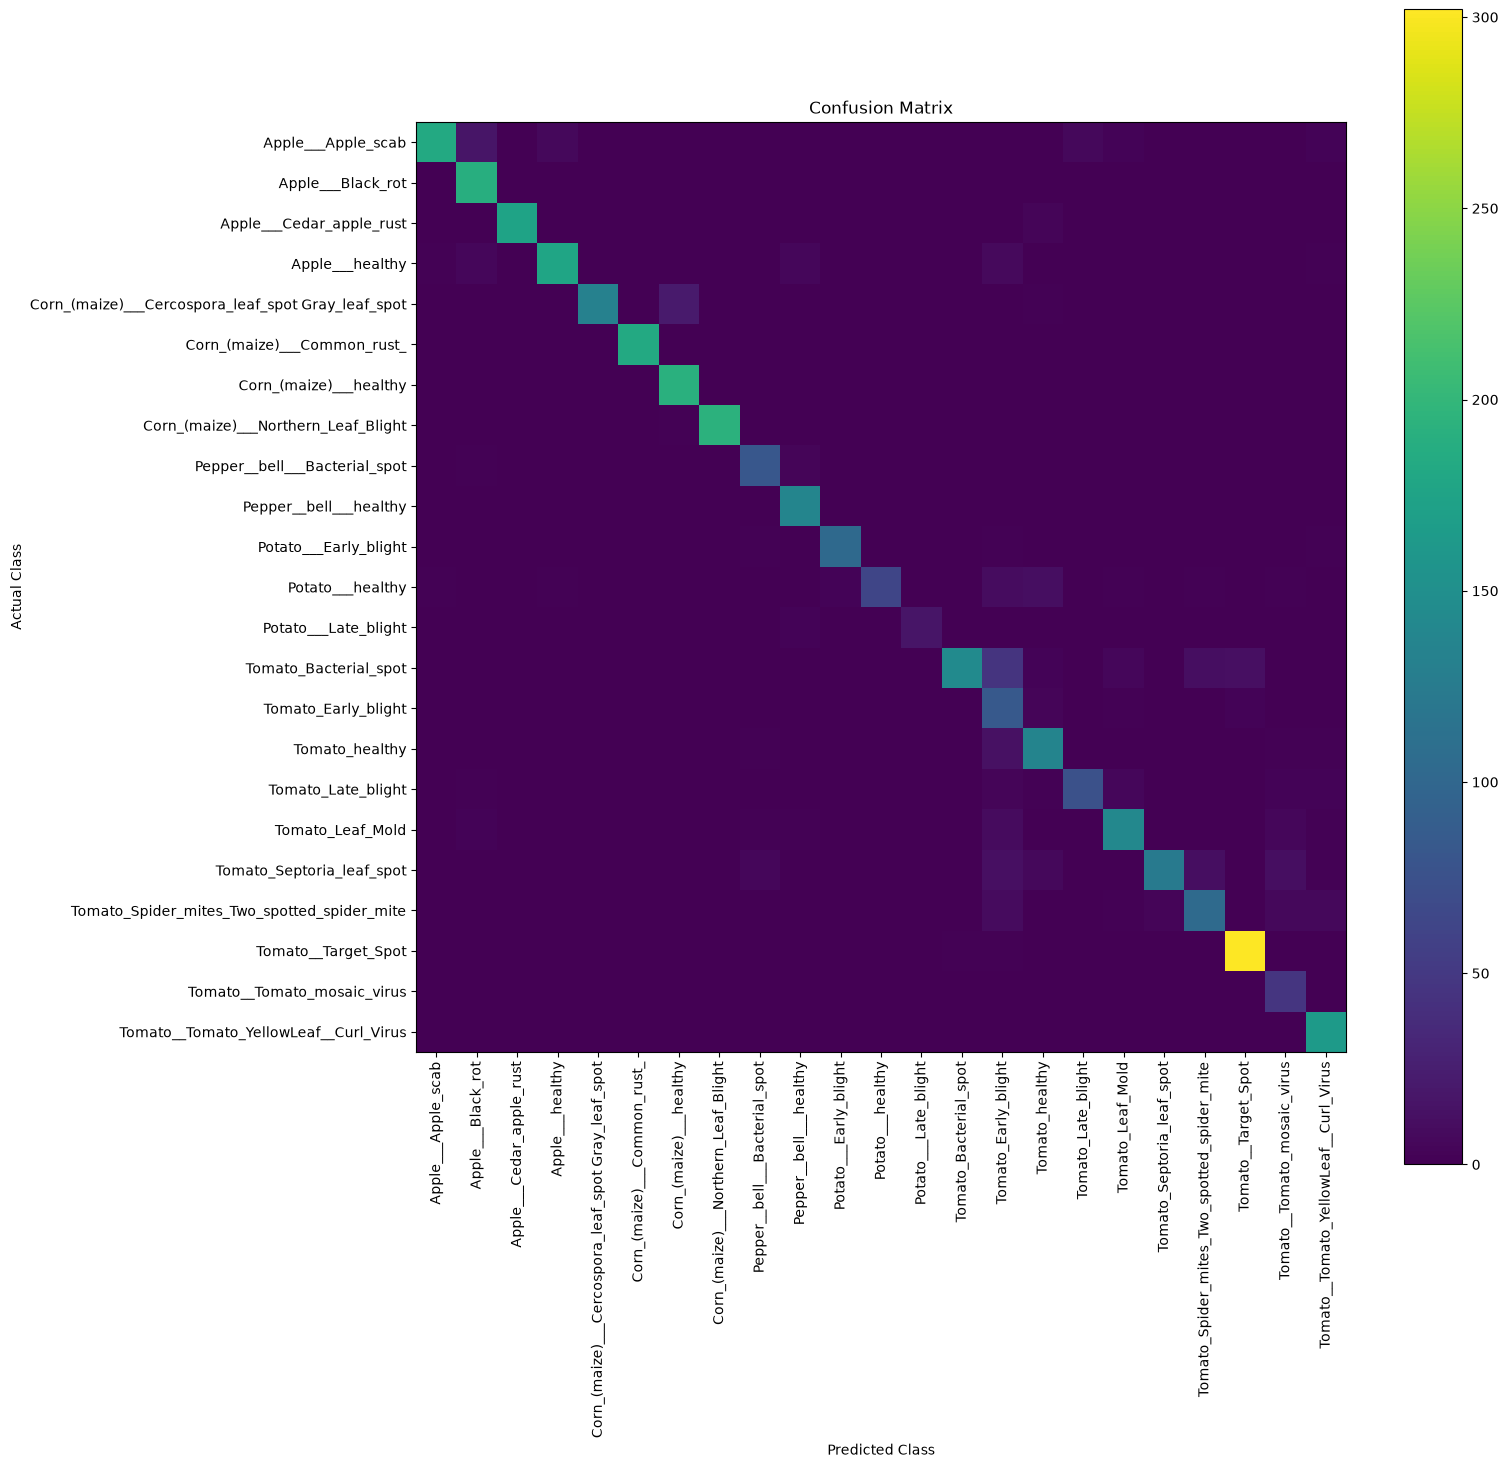

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 15))

plt.imshow(cm)

plt.colorbar()

plt.xticks(range(23), class_names, rotation=90)
plt.yticks(range(23), class_names)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")

plt.show()

In [37]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

print(report)

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.97      0.82      0.89       224
                                 Apple___Black_rot       0.87      0.98      0.92       192
                          Apple___Cedar_apple_rust       0.99      0.97      0.98       181
                                   Apple___healthy       0.93      0.87      0.90       204
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.97      0.83      0.90       160
                       Corn_(maize)___Common_rust_       1.00      0.99      0.99       186
                            Corn_(maize)___healthy       0.88      0.99      0.94       193
               Corn_(maize)___Northern_Leaf_Blight       0.99      0.98      0.99       197
                     Pepper__bell___Bacterial_spot       0.85      0.92      0.89        89
                            Pepper__bell___healthy       0.88      0.99      0.

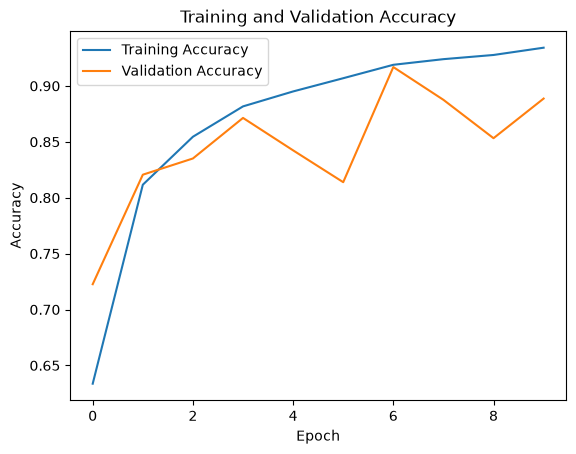

In [38]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend(["Training Accuracy", "Validation Accuracy"])

plt.show()

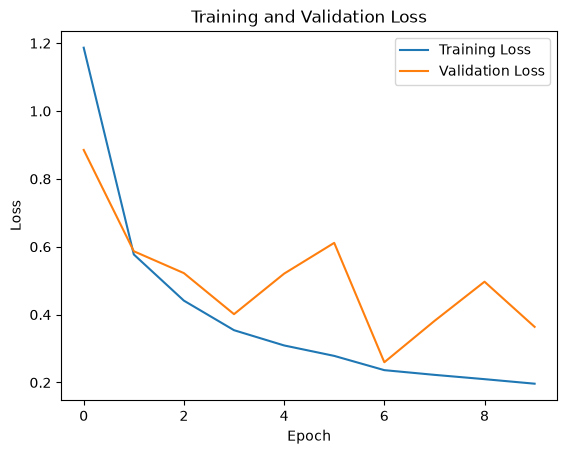

In [39]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend(["Training Loss", "Validation Loss"])

plt.show()

In [40]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

In [41]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    callbacks=[early_stopping]
)

Epoch 1/10


c:\Users\Hp\Desktop\Plant Disease Prediction\dl_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


893/893 ━━━━━━━━━━━━━━━━━━━━ 267s 298ms/step - accuracy: 0.9382 - loss: 0.1841 - val_accuracy: 0.8934 - val_loss: 0.3597
Epoch 2/10
893/893 ━━━━━━━━━━━━━━━━━━━━ 282s 316ms/step - accuracy: 0.9426 - loss: 0.1676 - val_accuracy: 0.9129 - val_loss: 0.3013
Epoch 3/10
893/893 ━━━━━━━━━━━━━━━━━━━━ 333s 372ms/step - accuracy: 0.9449 - loss: 0.1600 - val_accuracy: 0.8920 - val_loss: 0.3798
Epoch 4/10
893/893 ━━━━━━━━━━━━━━━━━━━━ 334s 373ms/step - accuracy: 0.9494 - loss: 0.1500 - val_accuracy: 0.9182 - val_loss: 0.2746
Epoch 5/10
893/893 ━━━━━━━━━━━━━━━━━━━━ 331s 370ms/step - accuracy: 0.9487 - loss: 0.1492 - val_accuracy: 0.8965 - val_loss: 0.3599
Epoch 6/10
893/893 ━━━━━━━━━━━━━━━━━━━━ 327s 367ms/step - accuracy: 0.9540 - loss: 0.1360 - val_accuracy: 0.9110 - val_loss: 0.3388


In [42]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Final Test Loss:", test_loss)
print("Final Test Accuracy:", test_accuracy)

112/112 ━━━━━━━━━━━━━━━━━━━━ 19s 73ms/step - accuracy: 0.9181 - loss: 0.2490
Final Test Loss: 0.24902409315109253
Final Test Accuracy: 0.9180925488471985


In [43]:
model.save("plant_disease_model.keras")

In [44]:
image_path = "archive (1)/dataset/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG"

img = tf.keras.utils.load_img(
    image_path,
    target_size=(128, 128)
)

img_array = tf.keras.utils.img_to_array(img)

img_array = img_array / 255.0

img_array = tf.expand_dims(img_array, 0)

In [45]:
predictions = model.predict(img_array)

predicted_class = np.argmax(predictions[0])

confidence = predictions[0][predicted_class] * 100

print("Predicted class:", class_names[predicted_class])
print("Confidence:", confidence, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step
Predicted class: Apple___Apple_scab
Confidence: 98.35121 %
